# Principled loss functions for continuous-time learning

**Haoping Qiu**, Mathematical Institute, University of Oxford, and DataSig.
Supervisors: Dr Sam Morley, Dr Ben Walker, Prof. Terry Lyons. Summer project, 3 August to 10 September 2026.

Models that map one time series to another are usually trained with pointwise mean squared error (MSE). This project asks which loss suits *path-to-path* learning, where inputs and outputs are whole continuous-time trajectories, and finds that the answer depends on what "close" should mean for the task.

Three experiments compare pointwise, elapsed-time, Sobolev and signature losses:

- **Experiment A** fits one fixed path with a Neural ODE and isolates how each loss shapes the learned curve.
- **Experiment B** learns a stream-to-stream operator, Brownian driver to Ornstein-Uhlenbeck response, with a Neural CDE.
- **Experiment C** plants small messages in Brownian rough paths and measures which distances notice them.

This notebook condenses the project presentation. It reads a small frozen extract of the original runs from `data/` and recomputes every figure and every number shown, so nothing here is typed in by hand. Training code, full run outputs and detailed analysis live in the main project repository. `data/PROVENANCE.json` records the source commit and a hash of every file read.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import figures

figures.use_style()
data = figures.load()
provenance = json.loads((figures.DATA / "PROVENANCE.json").read_text())
print("exported from commit", provenance["repository_git_sha"], "on", provenance["exported"][:10])

exported from commit f8cccc8 on 2026-10-14


## 1. Motivation

Observed time series are finite sequences of time-stamped values, and sequence models are trained on them with pointwise losses. Continuous-time models such as neural differential equations instead produce whole trajectories, so the loss decides how two *paths* are compared. Pointwise objectives can overfit local noise and miss temporal structure (Ramsay and Silverman, 2005; Kudrat et al., 2025).

### Pointwise agreement and path error

Let $0=t_0<\cdots<t_m=T$ be observation times and suppose two continuous predictions agree with the target at every one of them, $\widehat Y_A(t_j)=\widehat Y_B(t_j)=Y(t_j)$. Both have zero pointwise error,

$$
\operatorname{MSE}(\widehat Y,Y):=\frac1{m+1}\sum_{j=0}^{m}\lVert\widehat Y(t_j)-Y(t_j)\rVert_2^2=0,
$$

yet they can behave differently between observations, so their elapsed-time errors

$$
J_2(\widehat Y,Y):=\int_0^T\lVert\widehat Y(t)-Y(t)\rVert_2^2\,dt
$$

need not agree. Paths are stored at finitely many times, but the loss still determines how the underlying paths are compared.

### Path-to-path learning

Functional data analysis treats input $X$ and target $Y$ as whole paths in $C([0,T];\mathbb R^{d})$ (Ramsay and Silverman, 2005). A model is an operator $\mathcal F_\theta$ from input paths to predicted output paths, trained on pairs $(X^{(i)},Y^{(i)})_{i=1}^N$ by

$$
\widehat\theta\in\arg\min_\theta\frac1N\sum_{i=1}^N\mathcal L\bigl(\mathcal F_\theta(X^{(i)}),Y^{(i)}\bigr).
$$

Path loss $\mathcal L$ decides which discrepancies training treats as important.

### Losses compared

| Loss | Definition | Emphasis |
|---|---|---|
| Pointwise MSE | $\frac1{m+1}\sum_j\lVert\widehat Y(t_j)-Y(t_j)\rVert_2^2$ | each recorded point weighted equally |
| Elapsed-time $J_2$ | $\int_0^T\lVert\widehat Y(t)-Y(t)\rVert_2^2\,dt$ | error accumulated over time |
| Sobolev $H^1$ | $J_2(\widehat Y,Y)+\kappa\int_0^T\lVert\dot{\widehat Y}(t)-\dot Y(t)\rVert_2^2\,dt$ | values and local velocity, for smooth paths |
| Signature | $\lVert\Phi_M(\widehat Y)-\Phi_M(Y)\rVert_2^2$ | ordered increments and interactions through depth $M$ |

Here $\kappa>0$ balances value and derivative error, dots denote time derivatives, and $\Phi_M$ collects signature coordinates through level $M$. Every fitted path is evaluated under every metric, so no loss is judged only by its own score.

### Integral norms ignore order

For residual $e(t):=\widehat Y(t)-Y(t)$ and $1\le p<\infty$, set $\lVert e\rVert_{L^p}:=\bigl(\int_0^T\lVert e(t)\rVert_2^p\,dt\bigr)^{1/p}$. If $\tau:[0,T]\to[0,T]$ preserves elapsed time then $\lVert e\circ\tau\rVert_{L^p}=\lVert e\rVert_{L^p}$ (Lieb and Loss, 2001). Integral norms record the size and duration of an error, not the order in which its values occur. A second-level perturbation of a rough stream can leave every coordinate unchanged, and coordinate losses then respond by exactly zero.

### Path signatures

For a bounded-variation path $Y:[a,b]\to\mathbb R^d$, signature level $k$ is the iterated integral

$$
S^{(k)}(Y)_{a,b}:=\int_{a<t_1<\cdots<t_k<b}dY_{t_1}\otimes\cdots\otimes dY_{t_k},\qquad S^{(0)}:=1,
$$

with $\otimes$ the tensor product (Chen, 1957; Lyons et al., 2007; Chevyrev and Kormilitzin, 2016). Level 1 is net displacement. Level 2 records ordered pair interactions, and its antisymmetric part is signed area. Higher levels record finer ordered interactions. A *global* comparison uses one truncated signature over the whole interval; a *local* comparison uses signatures over a partition, retaining coarse information about where an ordered feature occurs.

## 2. Experiment A: fitting one fixed path

A Neural ODE is fitted repeatedly to one smooth two-dimensional target, with target data, initialisation and optimisation budget held fixed, so that only the training loss changes. With one target this is a controlled path-fitting study rather than operator learning: it exposes the geometry and optimisation behaviour of each loss before variation across input paths enters.

For $t\in[0,1]$ the target is

$$
a(t):=0.3\exp\bigl[-100(t-\tfrac14)^2\bigr],\qquad
Y^\star(t):=\begin{pmatrix}\cos(2\pi t)+a(t)\cos(12\pi t)\\ \sin(2\pi t)+a(t)\sin(12\pi t)\end{pmatrix}.
$$

A circle gives the broad shape and envelope $a$ adds a short oscillatory burst near $t=0.25$, which is easy to smooth away. Training sees 64 observations, either uniform in time or clustered late in the interval.

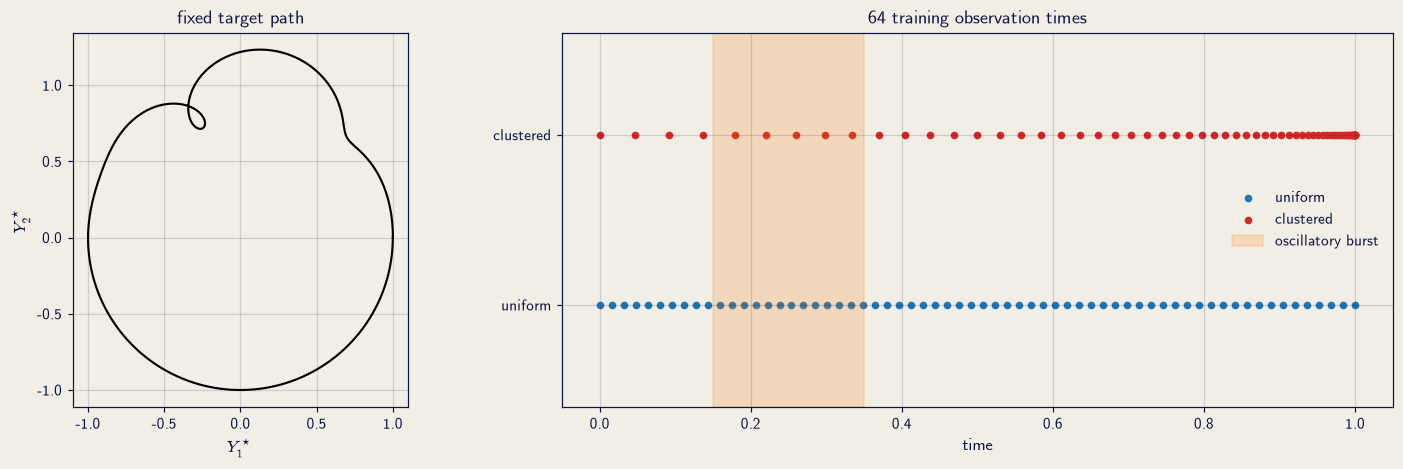

In [2]:
figure = figures.target_design(data)
if provenance["status"]["observation_times"] != "included":
    print("observation-time panel", provenance["status"]["observation_times"])

### Model

A Neural ODE generates a continuous fitted path (Chen et al., 2018):

$$
z_\theta(0)=z_{0,\theta},\qquad \dot z_\theta(t)=f_\theta\bigl(t,z_\theta(t)\bigr),\qquad \widehat Y_\theta(t)=g_\theta\bigl(z_\theta(t)\bigr),
$$

with $f_\theta$ a neural vector field and $g_\theta$ a decoder to two output coordinates. A *restricted* model has hidden dimension 2 and width 16; an *expressive* model has hidden dimension 8 and width 64. The vector field also receives five Fourier pairs $\{\sin(2^k\pi t),\cos(2^k\pi t)\}_{k=0}^4$ so it can represent the burst. Every fitted path is evaluated on the same dense grid under every metric.

### Signature losses

Signatures ignore where a path starts and how it is timed, so the output is time-augmented to $Z_Y(t):=(t,Y(t))\in\mathbb R^{3}$, and an anchor $A_0(\widehat Y,Y):=\frac12\lVert\widehat Y(0)-Y(0)\rVert_2^2$ restores the starting point. Writing $\Delta S^{(k)}_I$ for the level-$k$ signature difference of the augmented paths over interval $I$, and weighting level $k$ by $3^{-k}$ so its squared discrepancy is a mean per coordinate,

$$
\mathcal L_{\mathrm{global}}:=A_0+\sum_{k=1}^{4}3^{-k}\lVert\Delta S^{(k)}_{[0,1]}\rVert_2^2,
\qquad
\mathcal L_{\mathrm{local},K}:=A_0+\frac1K\sum_{b=1}^{K}\sum_{k=1}^{2}3^{-k}\lVert\Delta S^{(k)}_{I_b}\rVert_2^2,
$$

with $I_b=[(b-1)/K,b/K]$. The global loss measures overall ordered structure; the local loss keeps coarse temporal location. Experiment A first uses $K=10$.

### How each loss learns the path

Rows are training losses and columns are checkpoints, uniform observations, seed 0. Black is the target.

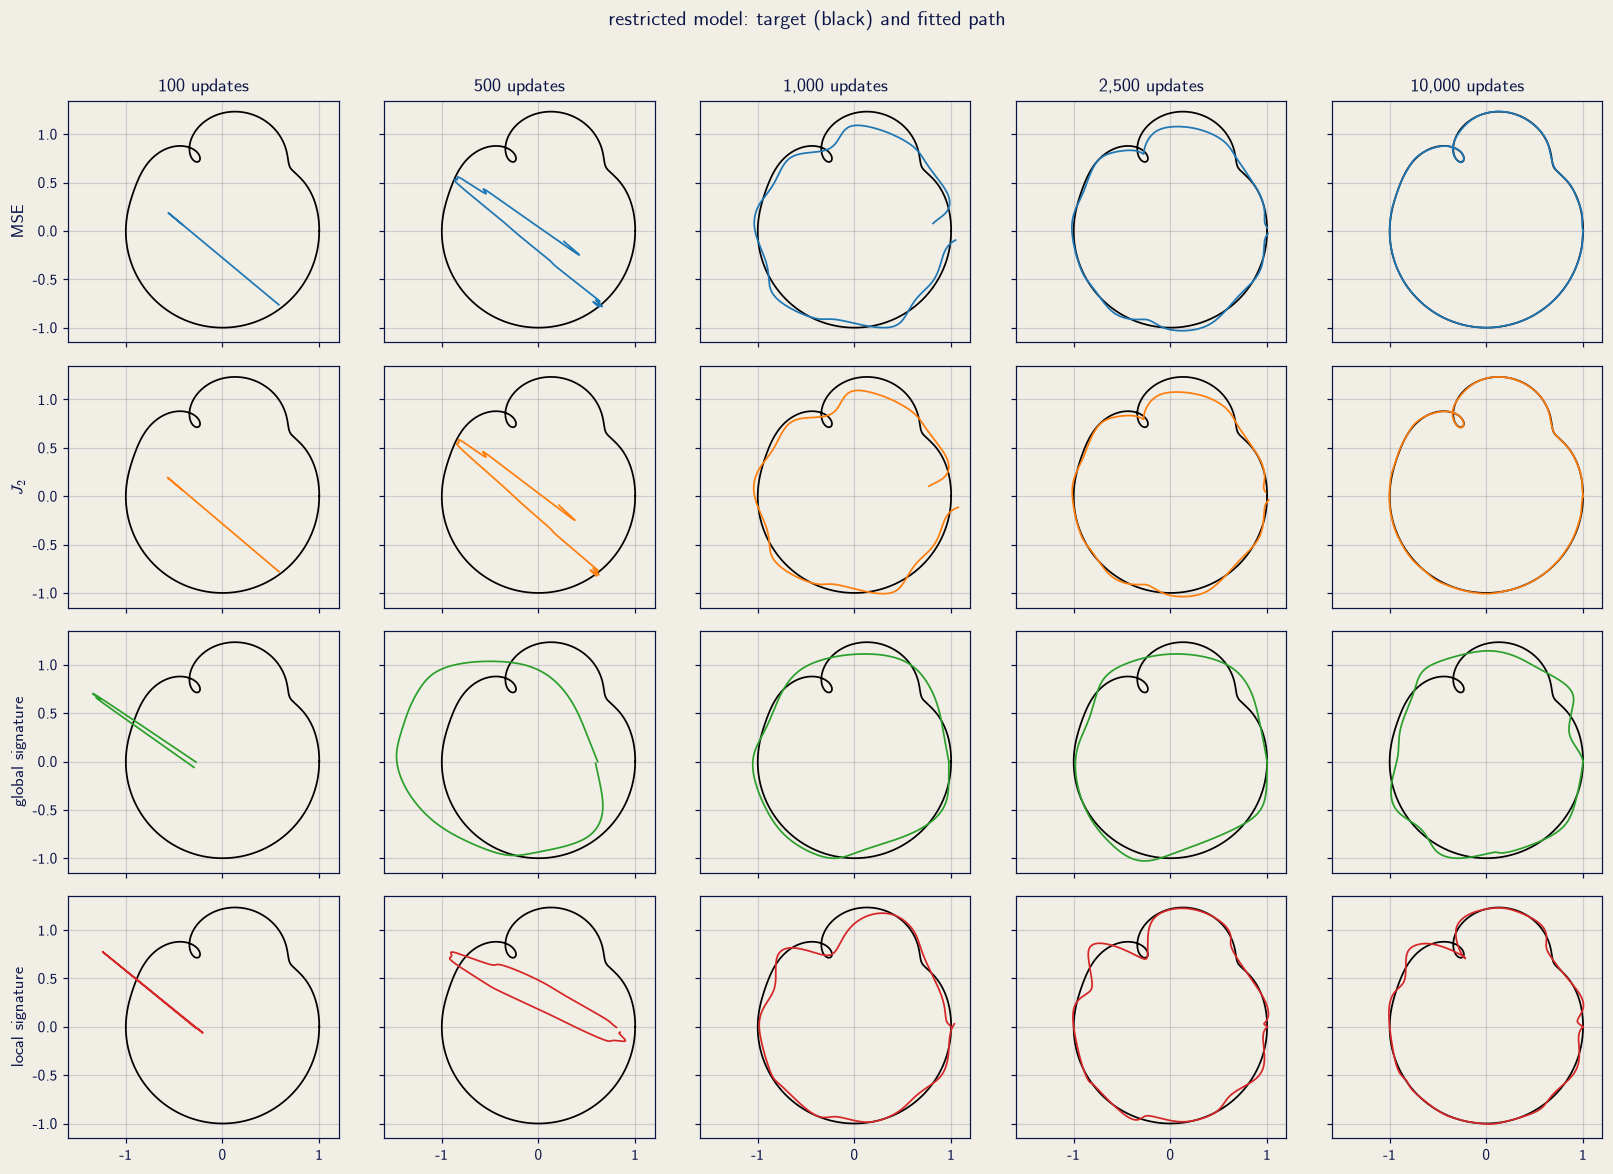

In [3]:
figure = figures.learning_paths(data, "restricted")

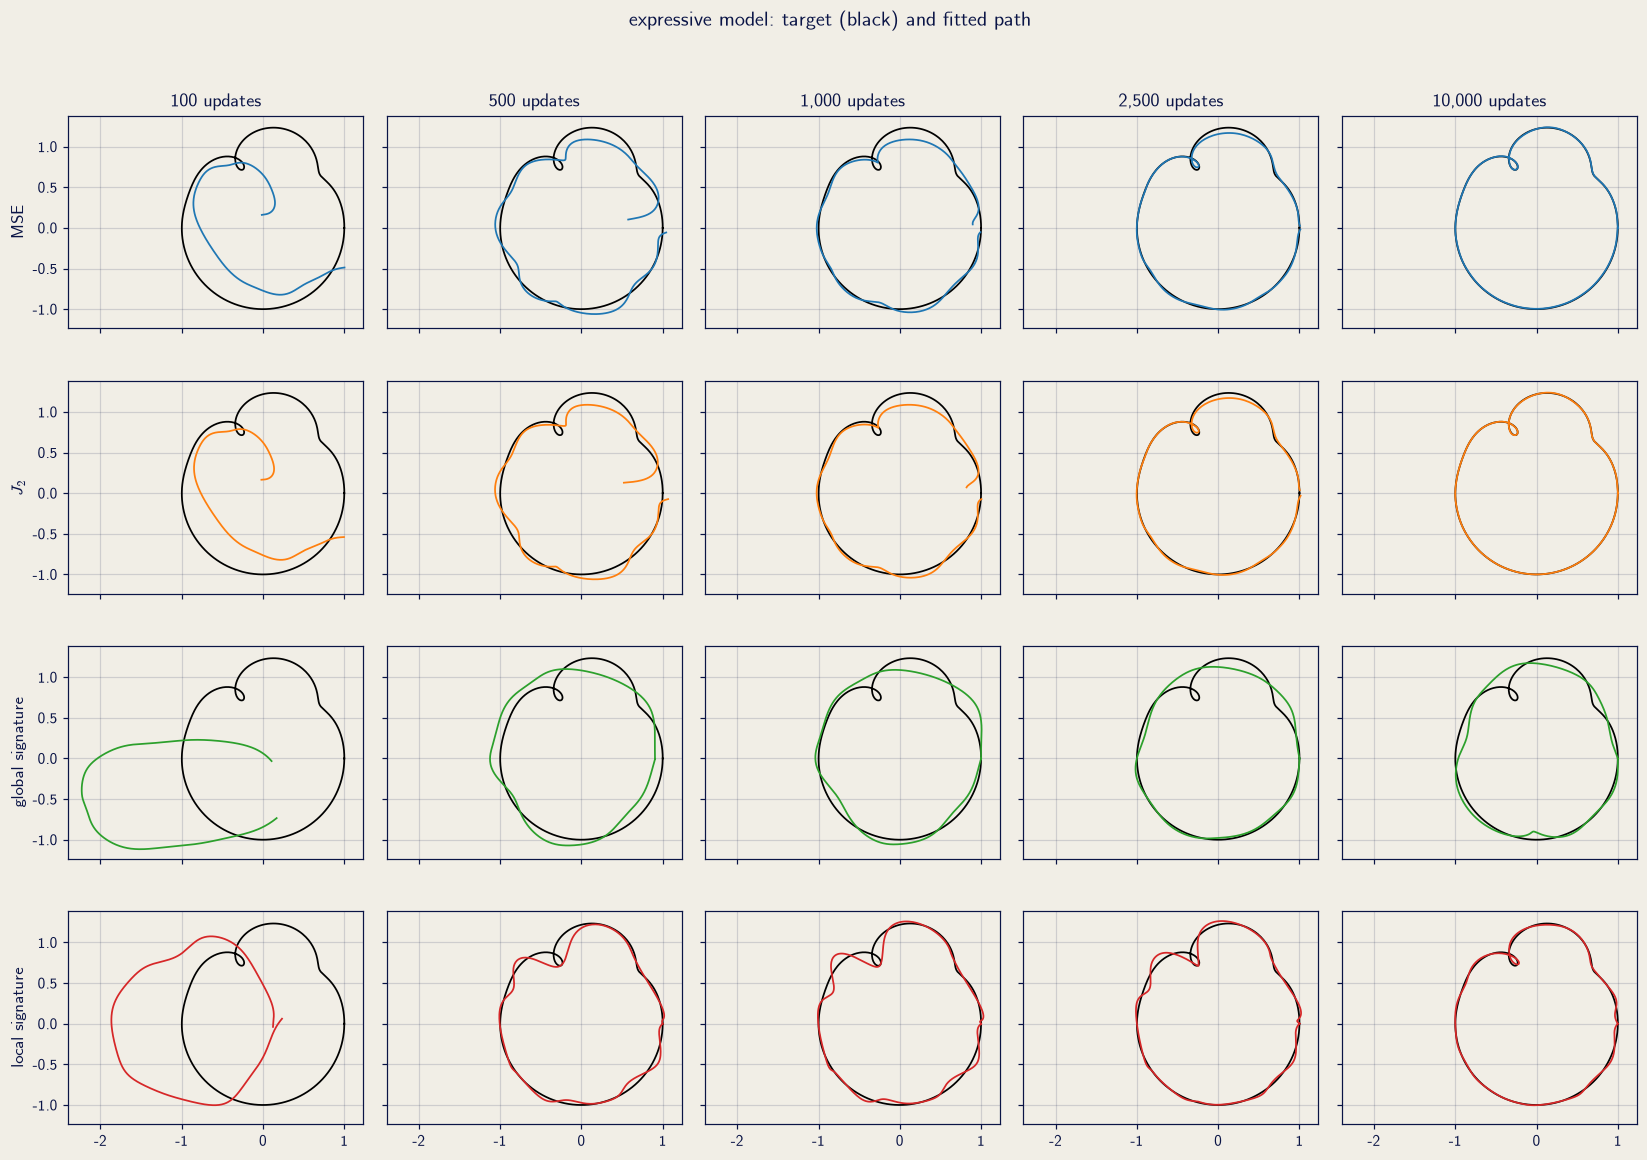

In [4]:
figure = figures.learning_paths(data, "expressive")

### Sampling density

MSE gives equal weight to every recorded point, so when observations cluster the cluster dominates training. $J_2$ uses quadrature weights that approximate elapsed time instead. One matched restricted-model pair under clustered sampling:

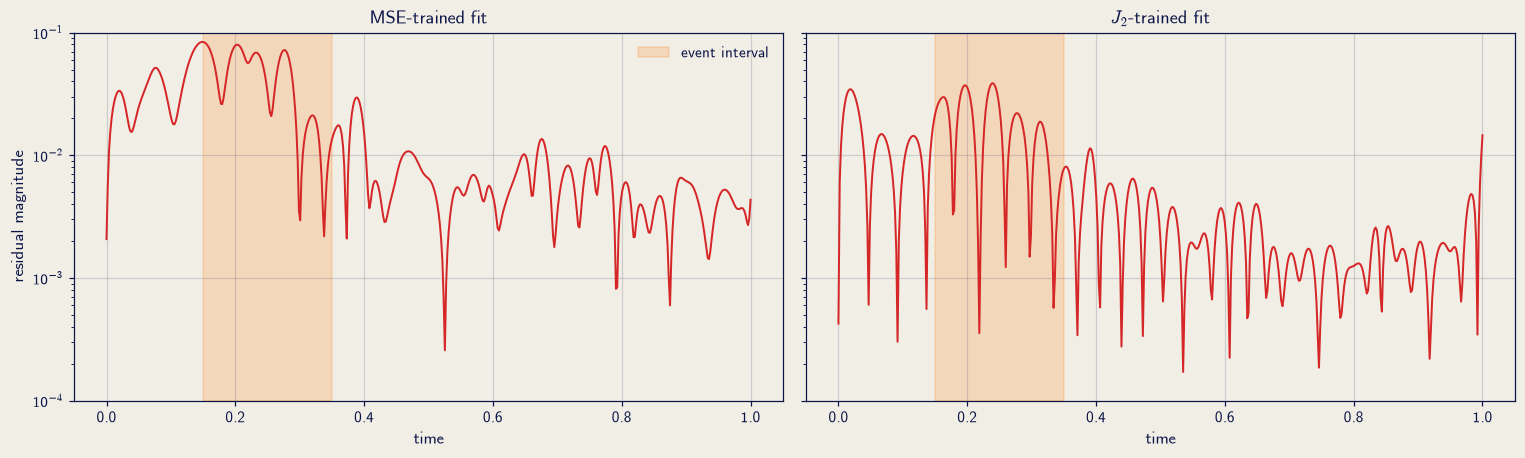

In [5]:
figure = figures.clustered_residuals(data)

Let $E^{\mathrm{MSE}}_{c,r}$ be dense evaluation MSE for the model trained with MSE at capacity $c$ and seed $r$, and $E^{J_2}_{c,r}$ the same for $J_2$ training. Over $R=3$ seeds, the reported reduction is a ratio of means,

$$
\operatorname{Reduction}_c:=1-\frac{R^{-1}\sum_r E^{J_2}_{c,r}}{R^{-1}\sum_r E^{\mathrm{MSE}}_{c,r}},
$$

which averages errors across seeds first and compares afterwards. Under clustered sampling $J_2$ wins every paired comparison; under uniform sampling the two objectives differ only through small endpoint weights and split the comparisons evenly.

In [6]:
final = data["fixed_final"]
pairs = final[final["loss"].isin(["mse", "j2"])].pivot_table(
    index=["capacity", "condition", "seed"], columns="loss", values="mse")
sampling = pairs.groupby(level=["capacity", "condition"]).agg(
    mse_trained=("mse", "mean"), j2_trained=("j2", "mean"))
sampling["reduction (%)"] = 100 * (1 - sampling["j2_trained"] / sampling["mse_trained"])
sampling["J2 wins"] = (pairs["j2"] < pairs["mse"]).groupby(level=["capacity", "condition"]).sum()
sampling["pairs"] = pairs.groupby(level=["capacity", "condition"]).size()
display(sampling.round({"reduction (%)": 1}))

clustered = sampling.xs("clustered", level="condition")
uniform = sampling.xs("uniform", level="condition")
assert (clustered["J2 wins"] == clustered["pairs"]).all()
assert uniform["J2 wins"].sum() * 2 == uniform["pairs"].sum()

mse_trained  j2_trained  reduction (%)  J2 wins  pairs
capacity   condition                                                        
expressive clustered     0.000142    0.000084           40.8        3      3
           uniform       0.000019    0.000031          -57.5        2      3
restricted clustered     0.000704    0.000222           68.4        3      3
           uniform       0.000020    0.000032          -57.0        1      3

### Derivative supervision

$H^1$ training directly penalises velocity error, so it resolves the short burst efficiently and gives the best general errors almost everywhere. That result depends on the smooth target, whose derivative is known analytically. Brownian paths lie almost surely outside $H^1$, so the same supervision is unavailable for rough streams, and signature losses are compared against this control rather than against MSE alone.

Below, each entry counts the capacity-seed groups (six in total, uniform sampling) in which a training loss has the lowest value of a metric at a given checkpoint.

In [7]:
checkpoints = data["fixed_checkpoints"]
metrics = ["mse", "h1", "linf", "local_j2", "sig_global", "sig_local"]
rows = []
for update in (500, 1000, 10000):
    at = checkpoints[checkpoints["update"] == update]
    for metric in metrics:
        winners = at.loc[at.groupby(["capacity", "seed"])[metric].idxmin(), "loss"].value_counts()
        rows.append({"update": update, "metric": metric, **winners.to_dict()})
winner_counts = (pd.DataFrame(rows).set_index(["update", "metric"])
                 .reindex(columns=["mse", "j2", "h1", "sig_global", "sig_local"])
                 .fillna(0).astype(int))
display(winner_counts)

general = ["mse", "h1", "linf", "local_j2"]
assert (winner_counts.loc[1000].loc[general, "h1"] == 6).all()
assert (winner_counts.loc[10000].loc[general, "h1"] >= 5).all()

mse  j2  h1  sig_global  sig_local
update metric                                        
500    mse           0   0   3           2          1
       h1            0   0   5           1          0
       linf          0   0   3           3          0
       local_j2      0   0   5           0          1
       sig_global    0   0   0           6          0
       sig_local     0   0   0           1          5
1000   mse           0   0   6           0          0
       h1            0   0   6           0          0
       linf          0   0   6           0          0
       local_j2      0   0   6           0          0
       sig_global    0   0   3           3          0
       sig_local     0   0   3           0          3
10000  mse           1   0   5           0          0
       h1            0   0   6           0          0
       linf          1   0   5           0          0
       local_j2      1   0   5           0          0
       sig_global    0   0   5           0          1
       sig_local     1   0   5           0          0

### Learning dynamics

Common metrics against Adam updates, restricted model, seed 0, uniform observations.

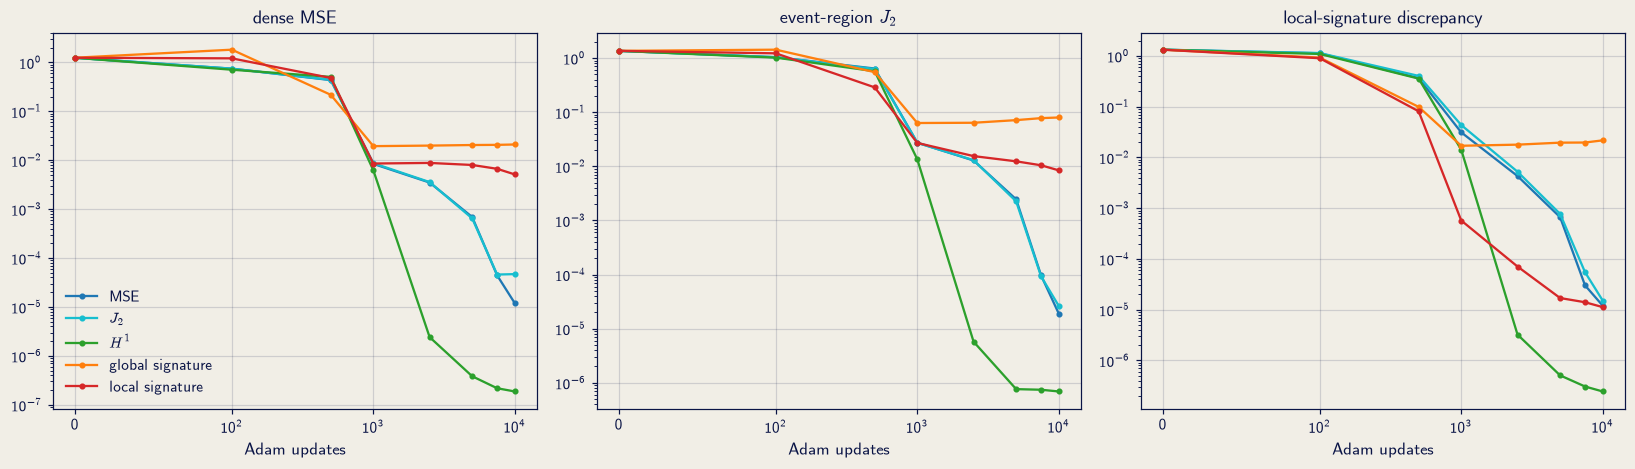

In [8]:
figure = figures.learning_dynamics(data)

**Early, objective-specific advantage.** At update 500 the global-signature objective has the lowest global-signature discrepancy in every group, and the local-signature objective leads on its own discrepancy in most groups (table above). Signature objectives change what is learned first, even when the final fit hides it.

**Recovery of the localised event.** Neither signature objective leads on error inside the oscillatory interval at that checkpoint; $H^1$ does, because it supervises velocity directly.

**Finite-budget conclusion.** Signature advantage is transient and objective-specific. Reporting only update 10,000 would hide it, and treating terminal paths as converged optima would overstate what the experiment shows.

In [9]:
assert winner_counts.loc[(500, "sig_global"), "sig_global"] == 6
assert winner_counts.loc[(500, "sig_local"), "sig_local"] > 3
assert winner_counts.loc[(500, "local_j2"), ["sig_global", "sig_local"]].max() <= 1

### Refining the local partition

Ten against one hundred local blocks, restricted model. Top: fitted paths. Bottom: residuals on a shared logarithmic scale. Finer blocks keep the location of the short oscillation more precisely, and refinement lowers every error metric below in every capacity-seed group.

100-block error divided by 10-block error (below 1 means refinement helps):


mse     j2     h1   linf  local_j2  sig_local_10  \
capacity   seed                                                       
expressive 0     0.000  0.000  0.001  0.009     0.000         0.005   
           1     0.000  0.000  0.001  0.008     0.000         0.009   
           2     0.002  0.002  0.000  0.027     0.001         0.054   
restricted 0     0.017  0.017  0.001  0.103     0.001         0.156   
           1     0.000  0.000  0.000  0.006     0.000         0.007   
           2     0.002  0.002  0.001  0.031     0.001         0.056   

                 sig_local_100_scaled  
capacity   seed                        
expressive 0                    0.000  
           1                    0.000  
           2                    0.000  
restricted 0                    0.000  
           1                    0.000  
           2                    0.001

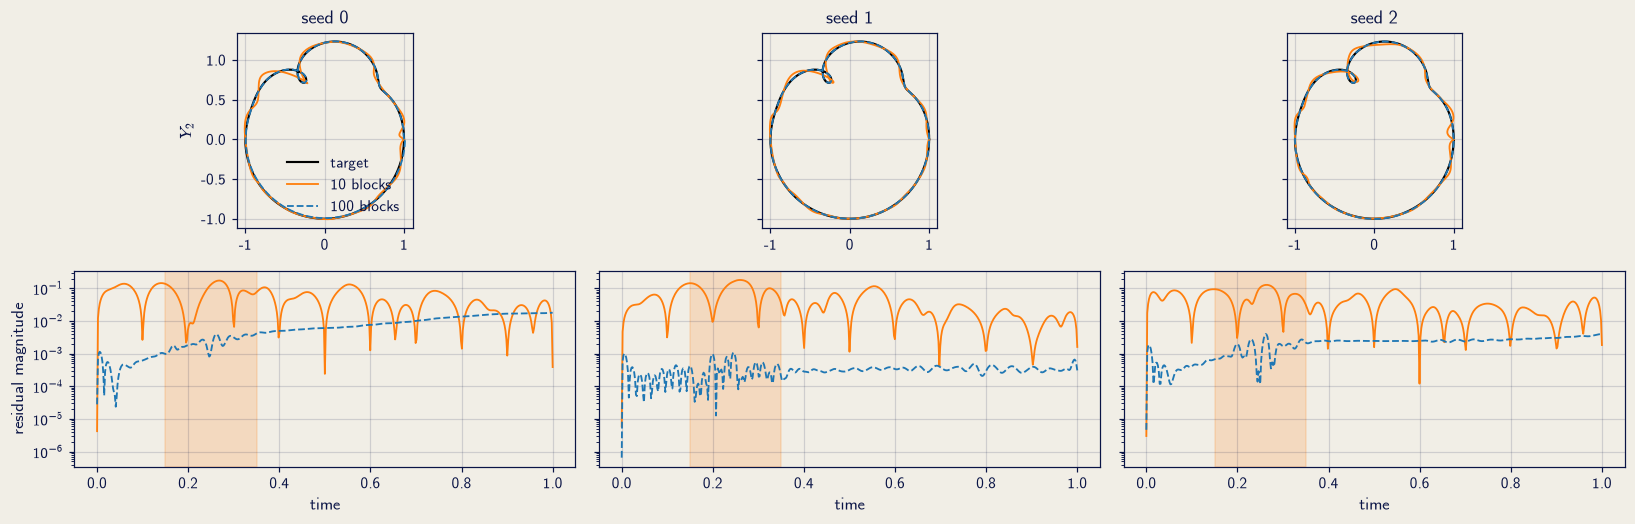

In [10]:
figure = figures.refinement_paths(data)

refinement = data["refinement"]
ratio_rows = []
for (capacity, seed), group in refinement.groupby(["capacity", "seed"]):
    indexed = group.set_index("training_loss")
    ratio_rows.append({"capacity": capacity, "seed": seed, **{
        m: indexed.loc["sig_local_fine", m] / indexed.loc["sig_local", m]
        for m in ["mse", "j2", "h1", "linf", "local_j2", "sig_local_10", "sig_local_100_scaled"]}})
ratios = pd.DataFrame(ratio_rows).set_index(["capacity", "seed"])
print("100-block error divided by 10-block error (below 1 means refinement helps):")
display(ratios.round(3))
assert (ratios < 1).all().all()

## 3. Experiment B: learning a stream-to-stream operator

Experiment B moves from fitting one curve to learning one rule that acts on many paths. The input is a whole Brownian driver on $[0,1]$ and the output is the whole Ornstein-Uhlenbeck (OU) response driven by that same stream, over the same interval: not forecasting, but path-to-path learning proper. It tests whether the sampling effect from Experiment A survives when the learned object is an operator.

For each path $i$, $dY^{(i)}_t=-2Y^{(i)}_t\,dt+0.5\,dW^{(i)}_t$ with $Y^{(i)}_0=0$, and the same Brownian increments define $W^{(i)}$ and $Y^{(i)}$. A Neural CDE learns $\mathcal F_\theta:W\mapsto\widehat Y$ (Kidger et al., 2020):

$$
dh^{(i)}_t=f_\theta(h^{(i)}_t)\,d\bigl(t,W^{(i)}_t\bigr),\qquad \widehat Y^{(i)}_\theta(t)=g_\theta(h^{(i)}_t).
$$

Hidden state $h$ evolves as the time-augmented driver moves; decoder $g_\theta$ reads it out. One set of parameters serves every path, so the model learns a rule rather than memorising curves. The study uses 512 training, 128 validation and 256 test pairs. Training sees 64 target times, uniform or clustered; within a matched comparison every loss gets the same paths, times, initialisation, minibatch order and 500-epoch budget. Test predictions are scored on all 257 time points under every metric, averaged over held-out paths and then over three seeds.

### An unseen driver

Clustered sampling, $J_2$ training, first test path.

maximum absolute residual on this path: 1.76e-03


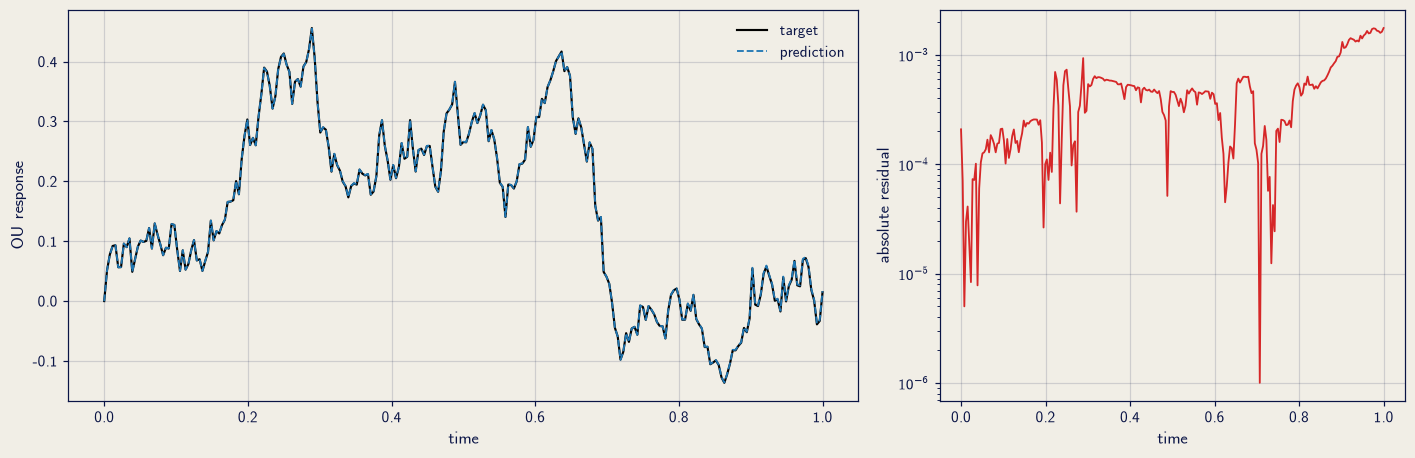

In [11]:
figure = figures.ou_response(data)
ou = data["ou"]
print(f"maximum absolute residual on this path: {np.abs(ou['prediction'] - ou['target']).max():.2e}")

### Results

**Elapsed-time weighting transfers to operator learning.** With uniform times MSE and $J_2$ training tie. With clustered times $J_2$ lowers dense test error in every seed, reproducing the mechanism isolated in Experiment A.

**Signature objectives change the learned operator but are less stable.** Local-signature training improves its own held-out discrepancy over both pointwise fits in most seeds. Remaining local runs and all global-signature runs are unstable at the final epoch, so they support no general superiority claim.

The OU operator is deliberately simple and learned to low absolute error. Its role is calibration: loss choice matters beyond single-path fitting.

In [12]:
test = data["ou_test"]
pointwise = test[test["loss"].isin(["mse", "j2"])]
means = pointwise.groupby(["condition", "loss"])[["fine_j2", "fine_mse"]].mean().unstack("loss")
summary = pd.DataFrame({
    "J2 lower test J2 (%)": 100 * (1 - means[("fine_j2", "j2")] / means[("fine_j2", "mse")]),
    "J2 lower test MSE (%)": 100 * (1 - means[("fine_mse", "j2")] / means[("fine_mse", "mse")]),
})
per_seed = pointwise.pivot_table(index=["condition", "seed"], columns="loss", values="fine_j2")
summary["seeds where J2 wins"] = (per_seed["j2"] < per_seed["mse"]).groupby(level="condition").sum()
display(summary.round(1))
assert summary.loc["clustered", "seeds where J2 wins"] == 3

uniform_runs = test[test["condition"] == "uniform"]
own = []
for seed, group in uniform_runs.groupby("seed"):
    indexed = group.set_index("loss")
    own.append({"seed": seed, "local signature / best pointwise, own discrepancy":
                indexed.loc["sig_local", "sig_local"] / indexed.loc[["mse", "j2"], "sig_local"].min()})
display(pd.DataFrame(own).set_index("seed").round(3))

,J2 lower test J2 (%),J2 lower test MSE (%),seeds where J2 wins
condition,,,
clustered,51.7,51.6,3
uniform,0.1,0.1,1


,"local signature / best pointwise, own discrepancy"
seed,
0,5.980
1,0.435
2,0.292


### Optimiser stability

Epoch-average training loss for the signature objectives, one curve per seed. Downward curves mean successful optimisation; upward spikes mean the optimiser left a better solution. Final checkpoints therefore reflect optimiser behaviour as well as path geometry, and signature results are reported at a fixed budget.

,global: final / best,local: final / best
seed 0,28.37,100.05
seed 1,28.54,2.64
seed 2,2.32,1.31


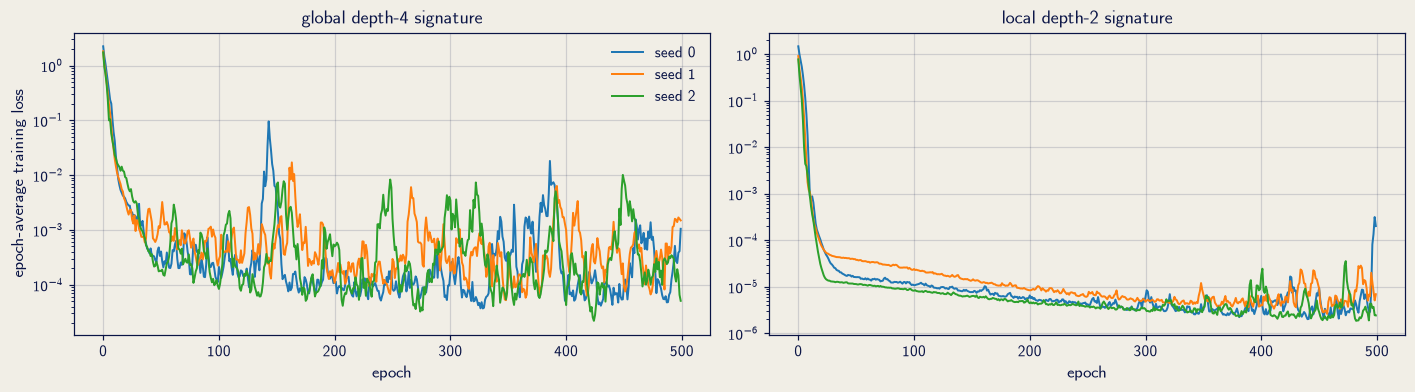

In [13]:
figure = figures.ou_signature_histories(data)
ratios = {
    loss: [ou[f"history_{loss}_seed{s}_train_loss"][-1] / ou[f"history_{loss}_seed{s}_train_loss"].min()
           for s in range(3)]
    for loss in ("sig_global", "sig_local")
}
display(pd.DataFrame(ratios, index=[f"seed {s}" for s in range(3)])
        .rename(columns={"sig_global": "global: final / best", "sig_local": "local: final / best"})
        .round(2))

## 4. Experiment C: messages hidden in Brownian streams

How small can a planted feature be before a path distance stops noticing it? Experiment C starts from 10,000 simulated four-dimensional Brownian rough paths and inserts messages of increasing strength into copies. No network is trained: each distance is tested directly, first on an original path against its own modified copy, then on whether it can separate unseen original and modified streams.

### Data

Each stream is a sequence of first-level increments and second-level Lévy areas, $X=\bigl((a_j,A_j)\bigr)_{j=0}^{2047}$ with $a_j\in\mathbb R^4$ and $A_j\in\Lambda^2\mathbb R^4$. Cumulative sums of $a_j$ give the visible Brownian path, which is all that MSE, $L^p$ and maximum error see. The six area coordinates record within-step ordering absent from that path, so an area-only message can change the rough path while leaving every coordinate unchanged. Simulation includes the joint Brownian area, which Gaussian increments alone do not determine (Wiktorsson, 2001; Foster and Habermann, 2023).

### Messages

A message modifies 16 consecutive steps near the middle of a stream. Its normalised amplitude $\rho$ measures the perturbation in units of the natural Brownian standard deviation at the affected level, from the exact null $\rho=0$ to $\rho=4$. The rough-path composition law is applied afterwards so every stream stays algebraically consistent.

| Message | Modifies | Probes |
|---|---|---|
| Increment | first-level increments $a_j$ | visible displacement |
| Area | second-level areas $A_j$ | hidden information, no coordinate change |
| Combined | both | mixed |
| Net template | all 16 perturbations one sign | accumulated change and endpoint displacement |
| Balanced template | eight positive then eight negative | local ordering with zero direct sum |

### Distances

| View | Distances | Information used |
|---|---|---|
| Coordinate | MSE, $J_2$, $L^1$, maximum error | visible motion |
| Rough path | direct area distance | stored second-level area |
| Global signature | variance-normalised, depth 4 | overall ordered structure |
| Local signature | variance-normalised, depth 2 | ordered structure within short blocks |
| Response-derived | $U_{r,4}$, $r\in\{0.5,1,2\}$ | levels weighted by a response scale |
| Truncated kernel | normalised inner product of depth-4 signatures | similarity in feature space |

For block $b$ and level $k$, let $\Delta S^{(k)}_b$ be the signature difference and $q_k^2$ the training variance per level-$k$ coordinate over unmodified streams. The variance-normalised distance is

$$
d_{\mathrm{var}}(X,Y):=\Bigl[\frac1B\sum_{b=1}^{B}\sum_{k=1}^{L}\frac{\lVert\Delta S^{(k)}_b\rVert_2^2}{4^k(q_k^2+\delta)}\Bigr]^{1/2},\qquad\delta=10^{-12},
$$

averaging over the $4^k$ coordinates and expressing discrepancy relative to ordinary Brownian variation. The response-derived distance $U_{r,L}:=\frac1B\sum_b\sum_{k\le L}r^k\lVert\Delta S^{(k)}_b\rVert_1$ is motivated by linear controlled differential equations, where level $k$ meets a product of $k$ response matrices of norm at most $r$ (Ferrucci, Perrée and Lyons, 2026). It is a project discrepancy, not a canonical signature metric.

### Aligned and offset partitions

A balanced message sums to zero over its 16 steps, so a depth-two signature over one block containing all of it can cancel. Shifting the partition by eight steps puts a boundary through the middle, and each half is compared separately. Both rows contain the same message; any difference between their distances comes from where the partition falls.

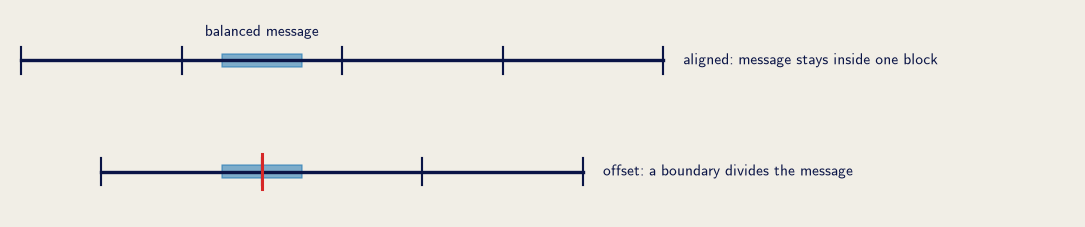

In [14]:
figure = figures.partition_schematic()

### Two sensitivity measures

*Paired sensitivity.* Pair each unmodified stream with a different unmodified stream, $\pi$, and take the natural scale $c_d:=\operatorname{median}_i d(X^{(i)},X^{(\pi(i))})$. For message $\tau$, amplitude $\rho$ and template $s$,

$$
R_d(\tau,\rho,s):=\frac{\operatorname{median}_i d\bigl(X^{(i)},\widetilde X^{(i)}_{\tau,\rho,s}\bigr)}{c_d},
$$

so $R_d=0$ means the distance sees nothing and $R_d=1$ means the message is as large as a typical difference between unrelated streams.

*Single-stream detection.* Given one stream, a one-nearest-neighbour classifier under distance $d$ labels it original or modified. It learns no feature map, so differences come from the distance alone. Performance is balanced accuracy, chance $1/2$. A message counts as detected at the smallest tested $\rho$ whose 95% lower confidence bound exceeds chance, and that threshold is re-tested on a separate 10,000-stream ensemble.

### Net against balanced templates

Combined message, paired sensitivity. Grey curves are the remaining distances.

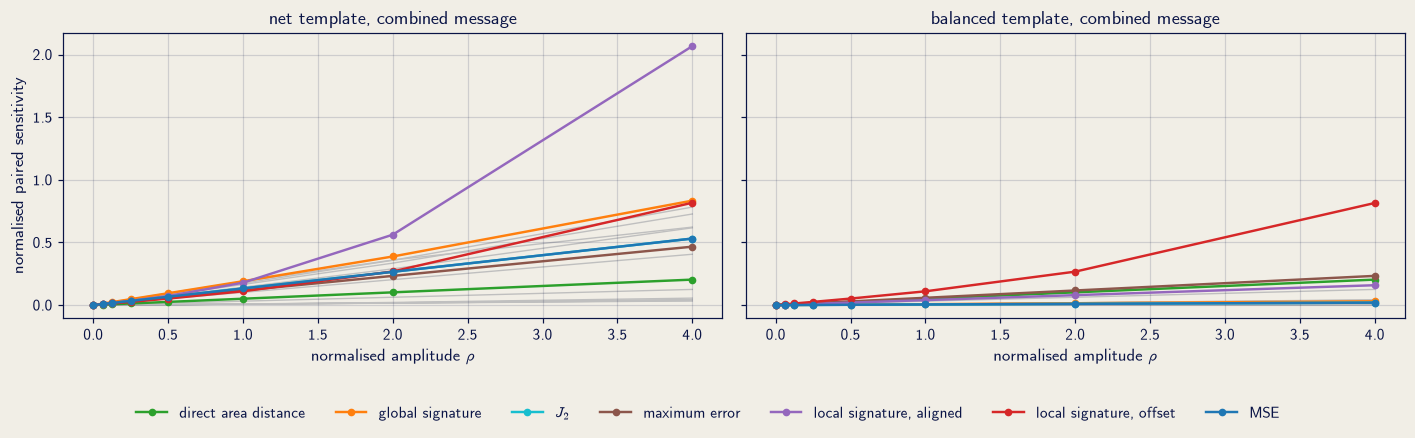

In [15]:
figure = figures.template_comparison(data)

With the net template perturbations accumulate, endpoint displacement is visible, and every highlighted distance responds. With the balanced template positive and negative halves cancel over the message block; most responses collapse, while the offset local signature stays strongly sensitive because its boundary separates the halves.

### Balanced messages: paired sensitivity

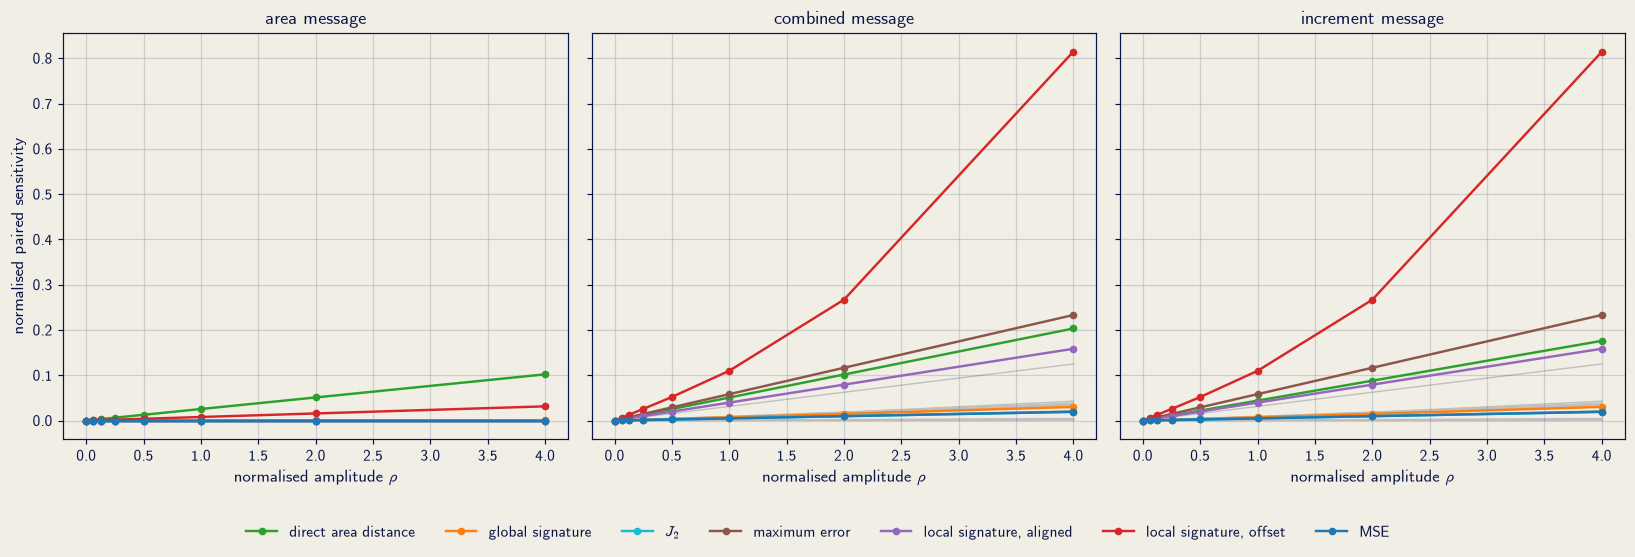

In [16]:
figure = figures.message_panels(data, "paired")

In the area-only panel coordinate distances stay at zero while direct area distance responds. In the combined and increment panels the offset local signature is most sensitive, since the partition prevents cancellation across the message.

### Balanced messages: held-out detection

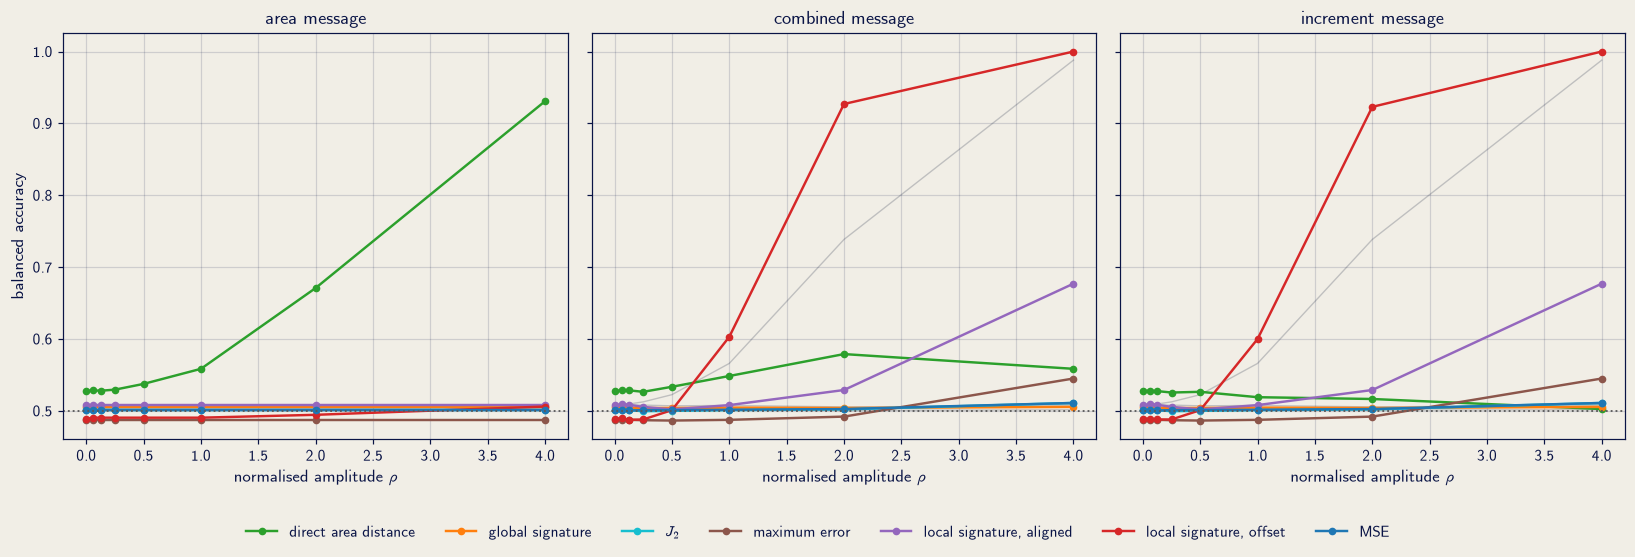

In [17]:
figure = figures.message_panels(data, "detection")

For area-only messages only direct area distance moves clearly above chance. For combined and increment messages the offset local signature separates the classes early and approaches perfect accuracy, the aligned local signature improves later, and MSE and $J_2$ stay near chance.

### Detection thresholds

First tested amplitude at which each distance passes the detection rule, balanced template, on the main ensemble and on the independent confirmation ensemble. Ordering differs from the paired-sensitivity plots: responding numerically to a known modification is not the same as population-level detectability.

In [18]:
thresholds = data["thresholds"]
balanced = thresholds[(thresholds["template"] == "balanced")
                      & thresholds["message_type"].isin(["increment", "combined"])]
table = balanced.pivot_table(index=["message_type", "representation"], columns="ensemble",
                             values="amplitude")
display(table)
both = table.dropna()
assert (both["main"] == both["confirmation"]).all()

ensemble                     confirmation  main
message_type representation                    
combined     area                     1.0   NaN
             increment                0.5   0.5
             linf                     4.0   4.0
             local_aligned            2.0   2.0
             local_offset             1.0   1.0
increment    area                     4.0   NaN
             increment                0.5   0.5
             linf                     4.0   4.0
             local_aligned            2.0   2.0
             local_offset             1.0   1.0

## 5. Conclusions

| Evidence | Main result | Meaning of closeness |
|---|---|---|
| Sampling limit | MSE targets a density-weighted integral | observation frequency |
| Fixed path and OU | $J_2$ corrects clustered bias | elapsed time |
| Smooth fixed path | $H^1$ resolves a short oscillatory burst | values and derivatives |
| Brownian messages | signature features detect area and order | ordered multilevel structure |

**Two paths count as close only relative to structure relevant to the task.** Observation density, regularity, scale, signature truncation, localisation and optimisation can each change the comparison.

Elapsed-time weights correct the emphasis created by irregular observation density. Derivative penalties are powerful when smooth derivatives are meaningful. Signature features are necessary when the relevant distinction is order or area rather than aligned coordinate error, but truncation, localisation and scaling are substantive modelling choices.

**Scope.** Evidence comes from one fixed target, one OU operator, one Brownian rough-path law, finite optimisation budgets and three training seeds. Signature training remains sensitive to optimisation, and detection thresholds depend on message support, sample size and classifier.

**Continuation.** Hybrid pointwise and signature losses, multiscale local signatures, learned path representations and broader stream-to-stream operators.

## References

- K.-T. Chen. Integration of paths, geometric invariants and a generalized Baker-Hausdorff formula. *Annals of Mathematics* 65(1):163-178, 1957.
- R. T. Q. Chen, Y. Rubanova, J. Bettencourt and D. K. Duvenaud. Neural ordinary differential equations. *NeurIPS* 31, 2018. arXiv:1806.07366.
- I. Chevyrev and A. Kormilitzin. A primer on the signature method in machine learning. arXiv:1603.03788, 2016.
- E. Ferrucci, O. Perrée and T. Lyons. Concise $(\varepsilon,r)$-representations of a path. arXiv:2607.26281, 2026.
- J. Foster and K. Habermann. Brownian bridge expansions for Lévy area approximations. *Combinatorics, Probability and Computing* 32(3):370-397, 2023.
- P. Kidger, J. Morrill, J. Foster and T. Lyons. Neural controlled differential equations for irregular time series. *NeurIPS* 33, 2020. arXiv:2005.08926.
- D. Kudrat et al. Patch-wise structural loss for time series forecasting. *ICML*, 2025.
- E. H. Lieb and M. Loss. *Analysis*, 2nd ed. American Mathematical Society, 2001.
- T. J. Lyons, M. Caruana and T. Lévy. *Differential Equations Driven by Rough Paths*. Lecture Notes in Mathematics 1908. Springer, 2007.
- J. O. Ramsay and B. W. Silverman. *Functional Data Analysis*, 2nd ed. Springer, 2005.
- M. Wiktorsson. Joint characteristic function and simultaneous simulation of iterated Itô integrals for multiple independent Brownian motions. *Annals of Applied Probability* 11(2):470-487, 2001.